# Lab 1: Understanding the Olist E-Commerce Dataset
**Prepared by:** Sharad Laad  
**Student Name:** Priyanshi Mali

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Show all columns and up to 100 rows when printing tables
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [3]:
DATA_DIR = Path("../data/raw")

# Verify that the folder exists and list all CSV files
print("Folder exists:", DATA_DIR.exists())
for file in DATA_DIR.glob("*.csv"):
    print("Found:", file.name)

Folder exists: True
Found: olist_customers_dataset.csv
Found: olist_geolocation_dataset.csv
Found: olist_orders_dataset.csv
Found: olist_order_items_dataset.csv
Found: olist_order_payments_dataset.csv
Found: olist_order_reviews_dataset.csv
Found: olist_products_dataset.csv
Found: olist_sellers_dataset.csv
Found: product_category_name_translation.csv


In [4]:
customers = pd.read_csv(DATA_DIR / "olist_customers_dataset.csv")
geolocation = pd.read_csv(DATA_DIR / "olist_geolocation_dataset.csv")
order_items = pd.read_csv(DATA_DIR / "olist_order_items_dataset.csv")
payments = pd.read_csv(DATA_DIR / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(DATA_DIR / "olist_order_reviews_dataset.csv")
orders = pd.read_csv(DATA_DIR / "olist_orders_dataset.csv")
products = pd.read_csv(DATA_DIR / "olist_products_dataset.csv")
sellers = pd.read_csv(DATA_DIR / "olist_sellers_dataset.csv")
category_translation = pd.read_csv(DATA_DIR / "product_category_name_translation.csv")

# Put them all into a dictionary so we can loop over them easily
tables = {
    "customers": customers,
    "geolocation": geolocation,
    "order_items": order_items,
    "payments": payments,
    "reviews": reviews,
    "orders": orders,
    "products": products,
    "sellers": sellers,
    "category_translation": category_translation
}

In [5]:
for name, df in tables.items():
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

customers: 99,441 rows, 5 columns
geolocation: 1,000,163 rows, 5 columns
order_items: 112,650 rows, 7 columns
payments: 103,886 rows, 5 columns
reviews: 99,224 rows, 7 columns
orders: 99,441 rows, 8 columns
products: 32,951 rows, 9 columns
sellers: 3,095 rows, 4 columns
category_translation: 71 rows, 2 columns


In [6]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [7]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [8]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [9]:
for name, df in tables.items():
    print("\n" + "=" * 60)
    print(f"INFO FOR: {name.upper()}")
    print("=" * 60)
    df.info()


INFO FOR: CUSTOMERS
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB

INFO FOR: GEOLOCATION
<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163

In [10]:
def summarize_table(name, df):
    return {
        "table_name": name,
        "rows": df.shape[0],
        "columns": df.shape[1],
        "missing_values": int(df.isnull().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum())
    }

summary = pd.DataFrame([summarize_table(name, df) for name, df in tables.items()])
display(summary)

# Save to reports folder
summary.to_csv("../reports/lab01_dataset_summary.csv", index=False)
print("Saved summary table to reports/lab01_dataset_summary.csv")

,table_name,rows,columns,missing_values,duplicate_rows
0,customers,99441,5,0,0
1,geolocation,1000163,5,0,261831
2,order_items,112650,7,0,0
3,payments,103886,5,0,0
4,reviews,99224,7,145903,0
5,orders,99441,8,4908,0
6,products,32951,9,2448,0
7,sellers,3095,4,0,0
8,category_translation,71,2,0,0


Saved summary table to reports/lab01_dataset_summary.csv


In [11]:
def missing_value_summary(df):
    missing_count = df.isnull().sum()
    missing_percent = (missing_count / len(df)) * 100
    res = pd.DataFrame({"missing_count": missing_count, "missing_percent": missing_percent})
    return res[res["missing_count"] > 0].sort_values(by="missing_percent", ascending=False)

for name, df in tables.items():
    missing_df = missing_value_summary(df)
    duplicates = df.duplicated().sum()
    print(f"\n--- {name.upper()} --- (Duplicates: {duplicates})")
    if not missing_df.empty:
        display(missing_df)
    else:
        print("No missing values.")


--- CUSTOMERS --- (Duplicates: 0)
No missing values.

--- GEOLOCATION --- (Duplicates: 261831)
No missing values.

--- ORDER_ITEMS --- (Duplicates: 0)
No missing values.

--- PAYMENTS --- (Duplicates: 0)
No missing values.

--- REVIEWS --- (Duplicates: 0)


,missing_count,missing_percent
review_comment_title,87656,88.341530
review_comment_message,58247,58.702532



--- ORDERS --- (Duplicates: 0)


,missing_count,missing_percent
order_delivered_customer_date,2965,2.981668
order_delivered_carrier_date,1783,1.793023
order_approved_at,160,0.160899



--- PRODUCTS --- (Duplicates: 0)


,missing_count,missing_percent
product_category_name,610,1.851234
product_name_lenght,610,1.851234
product_description_lenght,610,1.851234
product_photos_qty,610,1.851234
product_weight_g,2,0.006070
product_length_cm,2,0.006070
product_height_cm,2,0.006070
product_width_cm,2,0.006070



--- SELLERS --- (Duplicates: 0)
No missing values.

--- CATEGORY_TRANSLATION --- (Duplicates: 0)
No missing values.


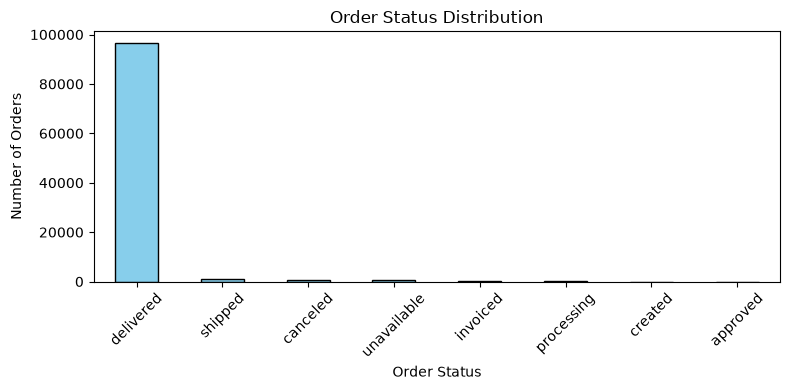

In [12]:
plt.figure(figsize=(8, 4))
orders["order_status"].value_counts().plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../figures/lab01_order_status_distribution.png")
plt.show()

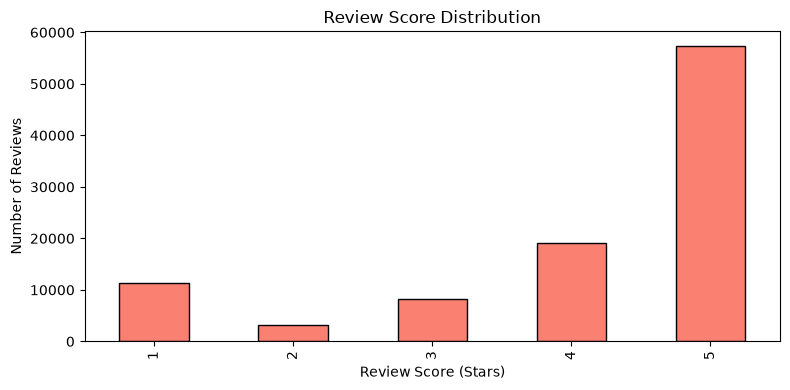

In [13]:
plt.figure(figsize=(8, 4))
reviews["review_score"].value_counts().sort_index().plot(kind="bar", color="salmon", edgecolor="black")
plt.title("Review Score Distribution")
plt.xlabel("Review Score (Stars)")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.savefig("../figures/lab01_review_score_distribution.png")
plt.show()

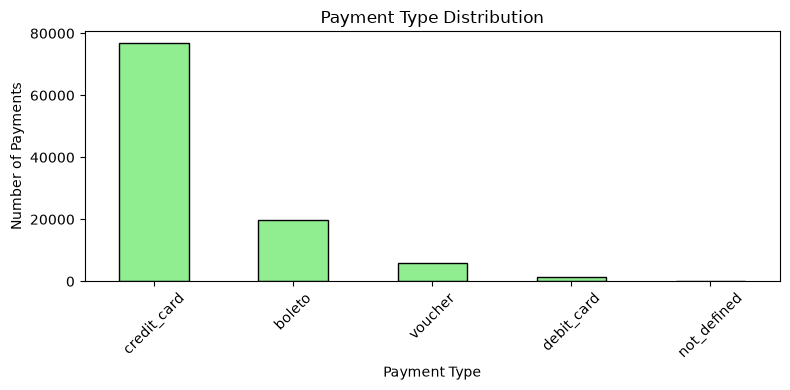

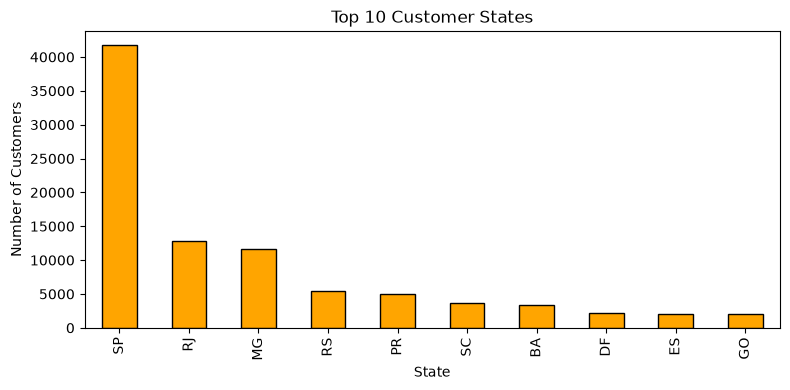

In [14]:
plt.figure(figsize=(8, 4))
payments["payment_type"].value_counts().plot(kind="bar", color="lightgreen", edgecolor="black")
plt.title("Payment Type Distribution")
plt.xlabel("Payment Type")
plt.ylabel("Number of Payments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../figures/lab01_payment_type_distribution.png")
plt.show()

plt.figure(figsize=(8, 4))
customers["customer_state"].value_counts().head(10).plot(kind="bar", color="orange", edgecolor="black")
plt.title("Top 10 Customer States")
plt.xlabel("State")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("../figures/lab01_top_customer_states.png")
plt.show()

In [15]:
print("1. Unique customers:", customers["customer_unique_id"].nunique())
print("2. Total orders:", orders["order_id"].nunique())
print("\n3. Common order statuses:\n", orders["order_status"].value_counts())
print("\n4. Common payment methods:\n", payments["payment_type"].value_counts())
print(f"\n5. Average review score: {reviews['review_score'].mean():.2f}")
print("\n6. Top 5 customer states:\n", customers["customer_state"].value_counts().head(5))

1. Unique customers: 96096
2. Total orders: 99441

3. Common order statuses:
 order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

4. Common payment methods:
 payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

5. Average review score: 4.09

6. Top 5 customer states:
 customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
Name: count, dtype: int64
